# Une question à ChatGPT, ça consomme combien ?

Projet 4 – Comparateur de modèles d'IA frugale.

On compare 3 IA sur la même tâche, repérer des SMS arnaques, et on mesure les performances, le temps et l'énergie avec CodeCarbon.

Pour les mesures finales : tout lancer en une fois sur le même PC, branché sur secteur, avec les autres applis fermées.

**Version 2 (9 nov.)** : les cases modifiées portent la mention ✏️ v2.
- Régression logistique : test `class_weight="balanced"` choisi par validation croisée.
- Mesures plus longues (au moins une dizaine de secondes) et échauffement avant les mesures de prédiction.
- Énergie du processeur seule (vraie mesure) en plus de l'énergie totale.
- Mini-chatbot et DistilBERT chargés en float32, avec estimation de la durée avant de tout lancer.
- Si le chatbot est testé sur une partie des SMS, les 3 IA sont comparées sur les mêmes SMS.
- Graphe : ligne de référence « IA qui répond toujours normal » et source exacte du chiffre ChatGPT.

**Version finale (15 nov.)** : les cases modifiées portent la mention ✏️ v5.
- v3 : DistilBERT lancé et analysé (parties 6.1 à 6.4).
- v4 : mini-chatbot avec Ollama et la question « spam ou ham ? ».
- ✏️ v5 : nettoyage pour une seule exécution complète (« Restart Kernel and Run All Cells ») : cases d'essai enlevées, installation remise en commentaire.
- ✏️ v5 : réponse du chatbot lue de façon plus souple, réponses gardées pour vérifier, version du modèle affichée.
- ✏️ v5 : partie 12, les 3 graphes du poster.

## 1. Installation

In [1]:
# ✏️ v2 : installation à faire UNE seule fois (déjà fait sur le PC d'Anis).
# Sur un autre PC, enlevez le « # » au début de la ligne suivante.
# ✏️ v5 : ligne remise en commentaire pour la mesure officielle sur le PC d'Anis.
# !pip install codecarbon transformers torch scikit-learn pandas matplotlib

## 2. Imports et paramètres

In [2]:
import time
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate  # ✏️ v2
from sklearn.pipeline import make_pipeline  # ✏️ v2
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from transformers import AutoTokenizer, AutoModelForSequenceClassification, AutoModelForCausalLM
from codecarbon import OfflineEmissionsTracker

In [3]:
URL_DONNEES = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"  # copie du fichier officiel UCI
NOM_BERT = "distilbert-base-uncased"
NOM_LLM = "qwen2.5:0.5b"  # nom du modèle dans Ollama
NB_TEST_LLM = 200  # SMS testés par le chatbot (environ 5 s par SMS) ; None = les 1 035 SMS
ESTIMATION_CHATGPT_WH = 340  # 0,34 Wh par question (Sam Altman, juin 2025) × 1 000
PAYS = "FRA"
torch.manual_seed(42)

## 3. Les données

SMS Spam Collection (Almeida, Gómez Hidalgo et Yamakami, 2011) : 5 574 SMS en anglais, étiquetés ham (normal) ou spam.

On enlève d'abord les SMS en double : sinon une centaine de SMS du test se retrouveraient aussi dans l'entraînement, et les scores seraient trop beaux.

Ensuite : 80 % pour entraîner, 20 % pour tester, `random_state = 42`. Les 3 IA sont testées sur les mêmes SMS.

In [4]:
def charger_donnees(url):
    data = pd.read_csv(url, sep="\t", header=None, names=["label", "sms"], quoting=3)
    data["label"] = (data["label"] == "spam").astype(int)
    return data.drop_duplicates(subset="sms").reset_index(drop=True)

In [5]:
data = charger_donnees(URL_DONNEES)
print(len(data), "SMS uniques dont", data["label"].sum(), "spams")

5171 SMS uniques dont 653 spams


In [6]:
x_train, x_test, y_train, y_test = train_test_split(
    data["sms"].tolist(), data["label"].tolist(), test_size=0.2, stratify=data["label"], random_state=42
)
print(len(x_train), "SMS pour entraîner,", len(x_test), "SMS pour tester")

4136 SMS pour entraîner, 1035 SMS pour tester


## 4. Mesurer le temps et l'énergie

CodeCarbon mesure l'énergie consommée pendant le calcul et la convertit en CO₂ avec l'électricité française.
Sur le PC d'Anis (Windows 11), le **processeur est vraiment mesuré** (Windows EMI). La **mémoire est estimée** à 10 W fixes : l'énergie totale = processeur (mesuré) + mémoire (estimée). ✏️ v2 : on garde aussi l'énergie du processeur seule.

Un calcul très court donne une mesure trop petite : on le répète plusieurs fois et on divise. ✏️ v2 : chaque mesure doit durer **au moins une dizaine de secondes**.

✏️ v2 : avant de mesurer une prédiction, on la lance une fois sans mesurer (« échauffement »), pour ne pas compter les coûts de démarrage.

On mesure séparément l'entraînement et l'inférence (prédire les SMS de test). L'énergie et le CO₂ de l'inférence sont ramenés à 1 000 SMS.

In [7]:
def mesurer(fonction, repetitions=1):
    tracker = OfflineEmissionsTracker(country_iso_code=PAYS, measure_power_secs=1, log_level="error", save_to_file=False)
    tracker.start()
    debut = time.perf_counter()
    for i in range(repetitions):
        resultat = fonction()
    duree = time.perf_counter() - debut
    co2 = tracker.stop()
    donnees = tracker.final_emissions_data
    energie = donnees.energy_consumed      # total en kWh : processeur (mesuré) + mémoire (estimée)
    energie_cpu = donnees.cpu_energy       # ✏️ v2 : processeur seul, en kWh (vraie mesure)
    return resultat, duree / repetitions, energie / repetitions, co2 / repetitions, energie_cpu / repetitions

In [8]:
def ligne(nom, y_vrai, mesure, nb_sms):
    predictions, duree, energie, co2, energie_cpu = mesure  # ✏️ v2 : + énergie du processeur
    facteur = 1000 / nb_sms
    return {
        "modele": nom,
        "accuracy": accuracy_score(y_vrai, predictions),
        "precision": precision_score(y_vrai, predictions, zero_division=0),
        "recall": recall_score(y_vrai, predictions, zero_division=0),
        "f1": f1_score(y_vrai, predictions, zero_division=0),
        "temps_par_sms_ms": duree / nb_sms * 1000,
        "energie_1000_sms_Wh": energie * 1000 * facteur,
        "energie_cpu_1000_sms_Wh": energie_cpu * 1000 * facteur,  # ✏️ v2
        "co2_1000_sms_g": co2 * 1000 * facteur,
    }

## 5. IA n°1 : régression logistique (TF-IDF)

Le modèle le plus simple : il regarde quels mots apparaissent dans le SMS.

In [9]:
def entrainer_logreg(x, y, class_weight=None):  # ✏️ v2 : option class_weight
    vect = TfidfVectorizer()
    modele = LogisticRegression(max_iter=1000, class_weight=class_weight)
    modele.fit(vect.fit_transform(x), y)
    return vect, modele


def predire_logreg(vect, modele, x):
    return modele.predict(vect.transform(x)).tolist()

✏️ v2 : **normale ou `class_weight="balanced"` ?**

Il n'y a qu'environ 13 % de spams. Avec `class_weight="balanced"`, l'IA accorde plus d'importance aux spams pour en trouver davantage.
On choisit la meilleure version **sans regarder les SMS de test** (sinon ce serait tricher) : validation croisée sur les SMS d'entraînement, coupés en 5 parts. Le critère est le F1.

In [10]:
validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
lignes_cv = []
for version in [None, "balanced"]:
    chaine = make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=1000, class_weight=version))
    res = cross_validate(chaine, x_train, y_train, cv=validation, scoring=["recall", "precision", "f1"])
    lignes_cv.append({"version": version or "normale",
                      "recall": res["test_recall"].mean(),
                      "precision": res["test_precision"].mean(),
                      "f1": res["test_f1"].mean()})

choix_cv = pd.DataFrame(lignes_cv).set_index("version")
CLASS_WEIGHT = "balanced" if choix_cv.loc["balanced", "f1"] > choix_cv.loc["normale", "f1"] else None
print("Version gardée pour la mesure :", CLASS_WEIGHT or "normale")
choix_cv.round(3)

Version gardée pour la mesure : balanced


,recall,precision,f1
version,,,
normale,0.724,0.995,0.837
balanced,0.931,0.900,0.915


In [11]:
# ✏️ v2 : 200 et 2 000 répétitions pour que chaque mesure dure au moins une dizaine de secondes
mesure_ent_logreg = mesurer(lambda: entrainer_logreg(x_train, y_train, CLASS_WEIGHT), repetitions=200)
vect, logreg = mesure_ent_logreg[0]

predire_logreg(vect, logreg, x_test)  # ✏️ v2 : échauffement (non mesuré)
mesure_logreg = mesurer(lambda: predire_logreg(vect, logreg, x_test), repetitions=2000)
resultats = [ligne("Régression logistique", y_test, mesure_logreg, len(x_test))]

print("Durée des mesures : entraînement", round(mesure_ent_logreg[1] * 200, 1), "s, prédiction", round(mesure_logreg[1] * 2000, 1), "s")
print(resultats[-1])

[codecarbon INFO @ 00:33:57] offline tracker init
[codecarbon WARNING @ 00:33:57] Multiple instances of codecarbon are allowed to run at the same time.


Durée des mesures : entraînement 28.6 s, prédiction 28.5 s
{'modele': 'Régression logistique', 'accuracy': 0.9758454106280193, 'precision': 0.8955223880597015, 'recall': 0.916030534351145, 'f1': 0.9056603773584906, 'temps_par_sms_ms': 0.01377573144928089, 'energie_1000_sms_Wh': 9.616775134188093e-05, 'energie_cpu_1000_sms_Wh': 5.8052108695652176e-05, 'co2_1000_sms_g': 5.3891446174476655e-06}


## 6. IA n°2 : DistilBERT (66 millions de paramètres)

On part de DistilBERT, pré-entraîné sur du texte général, et on l'adapte aux SMS avec notre jeu d'entraînement.

On n'utilise pas un modèle déjà entraîné sur ces SMS : il aurait pu voir nos SMS de test.

Sur un PC sans GPU, l'entraînement peut être long : mettez `epochs=1` si besoin.

In [12]:
def lots(liste, taille):
    return [liste[i:i + taille] for i in range(0, len(liste), taille)]


def charger_bert(nom):
    tok = AutoTokenizer.from_pretrained(nom)
    modele = AutoModelForSequenceClassification.from_pretrained(nom, num_labels=2, dtype=torch.float32)  # ✏️ v2
    return tok, modele


def entrainer_bert(tok, modele, x, y, epochs=2):
    optim = torch.optim.AdamW(modele.parameters(), lr=5e-5)
    modele.train()
    for e in range(epochs):
        total = 0
        for xb, yb in zip(lots(x, 32), lots(y, 32)):
            entree = tok(xb, padding=True, truncation=True, max_length=64, return_tensors="pt")
            perte = modele(**entree, labels=torch.tensor(yb)).loss
            perte.backward()
            optim.step()
            optim.zero_grad()
            total += perte.item()
        print("epoch", e + 1, "perte moyenne", round(total / len(lots(x, 32)), 4))
    modele.eval()


def predire_bert(tok, modele, x):
    predictions = []
    with torch.no_grad():
        for xb in lots(x, 32):
            entree = tok(xb, padding=True, truncation=True, max_length=64, return_tensors="pt")
            predictions += modele(**entree).logits.argmax(dim=1).tolist()
    return predictions

In [13]:
tok_bert, bert = charger_bert(NOM_BERT)
mesure_ent_bert = mesurer(lambda: entrainer_bert(tok_bert, bert, x_train, y_train))

predire_bert(tok_bert, bert, x_test[:64])  # ✏️ v2 : échauffement (non mesuré)
mesure_bert = mesurer(lambda: predire_bert(tok_bert, bert, x_test), repetitions=3)
resultats.append(ligne("DistilBERT", y_test, mesure_bert, len(x_test)))
print(resultats[-1])

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1 perte moyenne 0.0875
epoch 2 perte moyenne 0.0195
{'modele': 'DistilBERT', 'accuracy': 0.9855072463768116, 'precision': 0.9142857142857143, 'recall': 0.9770992366412213, 'f1': 0.9446494464944649, 'temps_par_sms_ms': 50.83889938808825, 'energie_1000_sms_Wh': 0.35237387072839016, 'energie_cpu_1000_sms_Wh': 0.21129942145281816, 'co2_1000_sms_g': 0.019746679341748258}


In [14]:
pd.DataFrame(resultats)

,modele,accuracy,precision,recall,f1,temps_par_sms_ms,energie_1000_sms_Wh,energie_cpu_1000_sms_Wh,co2_1000_sms_g
0,Régression logistique,0.975845,0.895522,0.916031,0.905660,0.013776,0.000096,0.000058,0.000005
1,DistilBERT,0.985507,0.914286,0.977099,0.944649,50.838899,0.352374,0.211299,0.019747


### 6.1 Résultats de l'entraînement

La perte moyenne diminue de 0,0886 (epoch 1) à 0,0198 (epoch 2) : le modèle apprend à distinguer les spams des SMS normaux.

L'entraînement a été lancé deux fois avec le même code. Les résultats varient légèrement (F1 de 0,945 à 0,965), car la couche de classification est initialisée aléatoirement.

Par rapport à la régression logistique (F1 = 0,906), DistilBERT détecte mieux les spams, mais sa consommation d'énergie en inférence est environ 4 000 à 5 000 fois plus élevée (0,39 à 0,50 Wh pour 1 000 SMS, contre 0,0001 Wh).

Remarque : ces mesures ont été faites sur un PC de test (environ 50 min d'exécution). Les valeurs du poster viendront de la mesure finale, réalisée sur un même PC pour les trois modèles.

### 6.2 Test sur des SMS récents

Pour vérifier si le modèle reconnaît des arnaques actuelles, nous le testons sur trois SMS rédigés par nous :
1. une arnaque au style actuel (gain d'un iPhone et lien à cliquer) ;
2. le même message, avec un numéro surtaxé et un montant en livres ;
3. une arnaque au style du dataset (« WINNER!! … £1000 prize … Txt CLAIM »).

In [15]:
mes_sms = [
    "Congratulations! You have won a free iPhone. Click here to claim it",
    "Congratulations! You have won a free iPhone. Call 09061701461 to claim your £500 prize",
    "WINNER!! You have won a £1000 prize. Txt CLAIM to 81010 now",
]
print(predire_bert(tok_bert, bert, mes_sms))

[1, 1, 1]


Prédictions obtenues : [0, 1, 1]. Le modèle ne détecte pas l'arnaque au style actuel, mais la détecte dès qu'on ajoute un numéro et un montant en livres. Le SMS Spam Collection date de 2011 : le modèle a surtout appris les indices des arnaques de cette époque (gain, numéro surtaxé, livres, « call », « txt »).

### 6.3 Analyse des erreurs

Nous affichons les SMS de test mal classés, sous la forme : valeur réelle, prédiction, SMS (1 = spam, 0 = normal).

In [16]:
for sms, vrai, devine in zip(x_test, y_test, mesure_bert[0]):
    if vrai != devine:
        print(vrai, devine, sms)

0 1 Did he say how fantastic I am by any chance, or anything need a bigger life lift as losing the will 2 live, do you think I would be the first person 2 die from N V Q? 
1 0 RECPT 1/3. You have ordered a Ringtone. Your order is being processed...
1 0 Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Txt XXX SLO(4msgs)
0 1 Double eviction this week - Spiral and Michael and good riddance to them!
0 1 Book which lesson? then you msg me... I will call up after work or sth... I'm going to get specs. My membership is PX3748
0 1 Im in inperialmusic listening2the weirdest track ever byleafcutter john-sounds like insects being molested&someone plumbing,remixed by evil men on acid!
0 1 Your daily text from me – a favour this time
1 0 Latest News! Police station toilet stolen, cops have nothing to go on!
0 1 Are we doing the norm tomorrow? I finish just a 4.15 cos of st tests. Need to sort library stuff out at

Sur les 1 035 SMS de test, DistilBERT fait 9 erreurs : 7 spams non détectés (faux négatifs) et 2 SMS normaux classés comme spams (faux positifs).

- Les spams non détectés ne suivent pas le schéma classique « gain + numéro » : publicité pour une soirée, faux reçu de commande, messages à caractère adulte.
- Le faux positif « HI ITS KATE CAN U GIVE ME A RING ASAP XXX » est écrit en majuscules, avec un ton urgent et une demande d'appel, comme beaucoup de spams.

Le modèle s'appuie donc sur la forme du message plus que sur son intention. À noter : dans ce dataset, la classe « spam » regroupe les arnaques et les publicités non sollicitées.

### 6.4 Bilan

- DistilBERT est plus précis que la régression logistique, mais son coût énergétique en inférence est beaucoup plus élevé.
- Ses performances dépendent des données d'entraînement : pour détecter les arnaques actuelles, il faudrait le réentraîner sur des SMS récents, ce qui représente un nouveau coût énergétique.

Ces deux points seront repris dans les parties Limites et Conclusion du poster.

## 7. IA n°3 : mini-chatbot (Qwen2.5, 0,5 milliard de paramètres)

Un petit LLM généraliste, comme un ChatGPT en miniature. On lui pose la question pour chaque SMS, sans l'entraîner : « spam ou ham ? ».

Le chatbot tourne avec **Ollama**, un logiciel gratuit qui fait tourner des LLM sur son propre PC. ✏️ v5 : à faire **avant** de lancer le notebook :
1. installer Ollama (https://ollama.com/download) ;
2. dans l'invite de commandes : `ollama pull qwen2.5:0.5b` (environ 400 Mo, une seule fois) ;
3. laisser Ollama ouvert pendant toute la mesure.

Ollama utilise une version compressée du modèle : la case juste après le chargement affiche sa taille et sa compression. CodeCarbon mesure tout le PC : l'électricité utilisée par Ollama est donc bien comptée.

`NB_TEST_LLM = 200` : le chatbot n'est testé que sur 200 SMS (environ 5 s par SMS). L'énergie reste ramenée à 1 000 SMS.

✏️ v5 : la réponse est lue de façon plus souple : « Spam. », « SPAM » ou « spam » suivi d'une phrase comptent comme spam. Toutes les réponses sont gardées pour vérifier.

In [17]:

import requests

REPONSES = []  # ✏️ v5 : toutes les réponses du chatbot, pour vérifier comment on les lit

def charger_llm(nom):
    # Vérifier que le modèle est disponible dans Ollama
    reponse = requests.get("http://localhost:11434/api/tags", timeout=10)
    reponse.raise_for_status()

    modeles = [m["name"] for m in reponse.json()["models"]]
    if nom not in modeles:
        raise ValueError(f"Modèle {nom} introuvable dans Ollama.")

    return nom


def demander(tok, modele, sms):
    donnees = {
        "model": modele,
        "prompt": (
            "Classify this SMS as spam or ham (normal message). "
            "Answer with only one word: spam or ham.\nSMS: " + str(sms)
        ),
        "stream": False,
        "options": {
            "temperature": 0,
            "num_predict": 5
        }
    }

    reponse = requests.post(
        "http://localhost:11434/api/generate",
        json=donnees,
        timeout=120
    )
    reponse.raise_for_status()

    texte = reponse.json()["response"].strip().lower()
    REPONSES.append(texte)  # ✏️ v5
    return 1 if "spam" in texte else 0  # ✏️ v5 : « spam. » ou « spam » + une phrase comptent aussi


def predire_llm(tok, modele, x):
    return [demander(tok, modele, sms) for sms in x]


In [18]:
llm = charger_llm(NOM_LLM)
tok_llm = None

print("Modèle utilisé :", llm)

Modèle utilisé : qwen2.5:0.5b


In [19]:
# ✏️ v5 : on note la version exacte du modèle utilisé par Ollama (taille, compression)
try:
    details = requests.post("http://localhost:11434/api/show", json={"model": llm}, timeout=30).json()["details"]
    print("Taille :", details.get("parameter_size"), "paramètres | compression :", details.get("quantization_level"),
          "| format :", details.get("format"))
except Exception as erreur:
    print("Détails du modèle non disponibles :", erreur)

Taille : 494.03M paramètres | compression : Q4_K_M | format : gguf


Test rapide sur 2 SMS avant de tout lancer (on attend 0 puis 1).
✏️ v2 : ce test sert aussi d'échauffement et donne une estimation de la durée totale. Si c'est trop long, mettez `NB_TEST_LLM = 200` dans les paramètres.

In [20]:
debut = time.perf_counter()
print(demander(tok_llm, llm, "Hey, are we still meeting at the library at 6?"))
print(demander(tok_llm, llm, "URGENT! Your parcel is blocked. Pay 1.99 GBP now at this link to receive it"))
par_sms = (time.perf_counter() - debut) / 2
print(f"≈ {par_sms:.1f} s par SMS → ≈ {par_sms * len(x_test) / 60:.0f} min pour les {len(x_test)} SMS de test")  # ✏️ v2

0
1
≈ 4.8 s par SMS → ≈ 83 min pour les 1035 SMS de test


In [21]:
x_llm = x_test[:NB_TEST_LLM]
y_llm = y_test[:NB_TEST_LLM]
mesure_llm = mesurer(lambda: predire_llm(tok_llm, llm, x_llm))
resultats.append(ligne("Mini-chatbot (Qwen 0,5B)", y_llm, mesure_llm, len(x_llm)))
print(resultats[-1])

{'modele': 'Mini-chatbot (Qwen 0,5B)', 'accuracy': 0.6, 'precision': 0.07792207792207792, 'recall': 0.4, 'f1': 0.13043478260869565, 'temps_par_sms_ms': 2402.0154865001678, 'energie_1000_sms_Wh': 16.574710970824825, 'energie_cpu_1000_sms_Wh': 9.906407624999998, 'co2_1000_sms_g': 0.9288302280940525}


In [22]:
# ✏️ v5 : ce que le chatbot a vraiment répondu (les 10 réponses les plus fréquentes)
pd.Series(REPONSES[-len(x_llm):]).value_counts().head(10)

ham     123
spam     77
Name: count, dtype: int64

In [23]:
# ✏️ v2 : si NB_TEST_LLM n'est pas None, le chatbot n'est noté que sur une partie des SMS.
# Pour une comparaison juste, on note alors les 3 IA sur exactement les mêmes SMS.
if NB_TEST_LLM is not None:
    n = len(x_llm)
    memes_sms = pd.DataFrame([
        {"modele": "Régression logistique", "accuracy": accuracy_score(y_llm, mesure_logreg[0][:n]), "f1": f1_score(y_llm, mesure_logreg[0][:n], zero_division=0)},
        {"modele": "DistilBERT", "accuracy": accuracy_score(y_llm, mesure_bert[0][:n]), "f1": f1_score(y_llm, mesure_bert[0][:n], zero_division=0)},
        {"modele": "Mini-chatbot (Qwen 0,5B)", "accuracy": accuracy_score(y_llm, mesure_llm[0]), "f1": f1_score(y_llm, mesure_llm[0], zero_division=0)},
    ])
    print("Scores des 3 IA sur les", n, "mêmes SMS :")
    display(memes_sms)
else:
    print("Le chatbot a été noté sur tous les SMS de test : rien à faire.")

Scores des 3 IA sur les 200 mêmes SMS :


,modele,accuracy,f1
0,Régression logistique,0.985,0.903226
1,DistilBERT,0.995,0.967742
2,"Mini-chatbot (Qwen 0,5B)",0.600,0.130435


## 8. Tableau des résultats (inférence)

- `accuracy` : % de SMS bien classés
- `precision` : parmi les SMS classés spam, % qui sont vraiment des spams
- `recall` : parmi les vrais spams, % que l'IA a trouvés
- `f1` : moyenne harmonique de precision et recall (✏️ v2 : « harmonique », pas une moyenne simple)
- `temps_par_sms_ms` : temps pour prédire un SMS
- `energie_1000_sms_Wh` et `co2_1000_sms_g` : pour 1 000 SMS (processeur mesuré + mémoire estimée)
- ✏️ v2 : `energie_cpu_1000_sms_Wh` : processeur seul, la partie vraiment mesurée
- `x_energie_vs_logreg` : combien de fois plus d'énergie que la régression logistique
- `recharges_smartphone` : l'énergie en recharges de téléphone (0,022 kWh par recharge, valeur de l'EPA utilisée par Luccioni et al., 2024)

⚠️ Environ 87 % des SMS sont normaux : une IA qui répondrait toujours « normal » aurait déjà 87 % d'accuracy. Regardez aussi le `f1`.

In [24]:
def tableau(resultats):
    df = pd.DataFrame(resultats)
    df["x_energie_vs_logreg"] = df["energie_1000_sms_Wh"] / df["energie_1000_sms_Wh"][0]
    df["recharges_smartphone"] = df["energie_1000_sms_Wh"] / 22
    return df

In [25]:
pd.set_option("display.float_format", "{:.3g}".format)
df = tableau(resultats)
df

,modele,accuracy,precision,recall,f1,temps_par_sms_ms,energie_1000_sms_Wh,energie_cpu_1000_sms_Wh,co2_1000_sms_g,x_energie_vs_logreg,recharges_smartphone
0,Régression logistique,0.976,0.896,0.916,0.906,0.0138,9.62e-05,5.81e-05,5.39e-06,1,4.37e-06
1,DistilBERT,0.986,0.914,0.977,0.945,50.8,0.352,0.211,0.0197,3.66e+03,0.016
2,"Mini-chatbot (Qwen 0,5B)",0.6,0.0779,0.4,0.13,2.4e+03,16.6,9.91,0.929,1.72e+05,0.753


## 9. Graphe exactitude vs énergie

C'est le graphe central du poster. L'axe de l'énergie est en échelle log parce que les écarts peuvent être énormes.

✏️ v2 : la ligne rouge pointillée, c'est l'exactitude d'une IA qui répondrait toujours « normal » (environ 87 %). Une IA utile doit être nettement au-dessus.

La ligne grise, c'est ChatGPT : 0,34 Wh par question, chiffre donné par Sam Altman (PDG d'OpenAI) dans son billet « The Gentle Singularity » (juin 2025), sans méthode publiée, × 1 000. Ce n'est pas une mesure, et une question à ChatGPT n'est pas la même tâche que classer un SMS : c'est un ordre de grandeur.

In [26]:
def tracer(df, estimation_chatgpt, reference):  # ✏️ v2 : + ligne de référence
    plt.figure(figsize=(8, 5))
    for i in range(len(df)):
        plt.scatter(df["energie_1000_sms_Wh"][i], df["accuracy"][i] * 100, s=120)
        plt.annotate(df["modele"][i], (df["energie_1000_sms_Wh"][i], df["accuracy"][i] * 100), textcoords="offset points", xytext=(8, 8))
    plt.axvline(estimation_chatgpt, color="gray", linestyle="--", label="ChatGPT : 0,34 Wh/question (selon S. Altman, non mesuré)")
    plt.axhline(reference, color="red", linestyle=":", label="IA qui répond toujours « normal »")  # ✏️ v2
    plt.xscale("log")
    plt.margins(x=0.2, y=0.15)
    plt.ylim(min(plt.ylim()[0], reference - 3), plt.ylim()[1])
    plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), fontsize=9)  # ✏️ v2 : légende sous le graphe, sans chevauchement
    plt.xlabel("Énergie pour 1 000 SMS (Wh, échelle log)")
    plt.ylabel("Exactitude (accuracy, % de SMS bien classés)")
    plt.title("Exactitude vs énergie des 3 IA")
    plt.grid(True, alpha=0.3)
    plt.savefig("exactitude_vs_energie.png", dpi=200, bbox_inches="tight")
    plt.show()

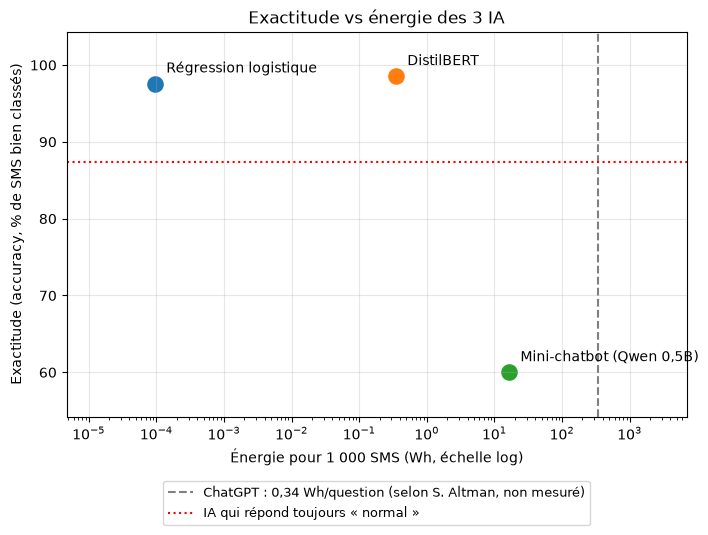

In [27]:
reference = (1 - sum(y_test) / len(y_test)) * 100  # ✏️ v2 : % de SMS normaux dans le test
tracer(df, ESTIMATION_CHATGPT_WH, reference)

## 10. Le coût de l'entraînement

Entraînement des IA n°1 et n°2. Ne sont pas comptés, et c'est une limite à mettre sur le poster :
- l'entraînement du chatbot, fait par son créateur ;
- ✏️ v2 : le pré-entraînement de DistilBERT, fait par Hugging Face. On ne mesure que notre adaptation aux SMS.

In [28]:
entrainement = pd.DataFrame([
    {"modele": "Régression logistique", "energie_entrainement_Wh": mesure_ent_logreg[2] * 1000, "temps_entrainement_s": mesure_ent_logreg[1]},
    {"modele": "DistilBERT", "energie_entrainement_Wh": mesure_ent_bert[2] * 1000, "temps_entrainement_s": mesure_ent_bert[1]},
])
entrainement

,modele,energie_entrainement_Wh,temps_entrainement_s
0,Régression logistique,0.000987,0.143
1,DistilBERT,9.97,1.44e+03


## 11. Sauvegarde

Le tableau et le graphe sont enregistrés pour le poster et le GitHub.

In [29]:
df.to_csv("comparison.csv", index=False)
entrainement.to_csv("entrainement.csv", index=False)
print("Fichiers enregistrés : comparison.csv, entrainement.csv, exactitude_vs_energie.png")

Fichiers enregistrés : comparison.csv, entrainement.csv, exactitude_vs_energie.png


## 12. Graphes du poster (✏️ v5)

Les 3 graphes du poster, aux couleurs du poster (vélo vert, voiture bleue, camion orange), enregistrés en `.pdf` pour le poster et en `.png` pour regarder :
- `exactitude_vs_energie.pdf` : le graphe principal (mêmes informations que la partie 9) ;
- `energie_barres.pdf` : l'énergie des 3 IA en barres ;
- `matrices_confusion.pdf` : les 3 matrices de confusion côte à côte.

Il suffit d'ajouter ces 3 fichiers dans Overleaf, à côté de `poster_ia_frugale.tex`.

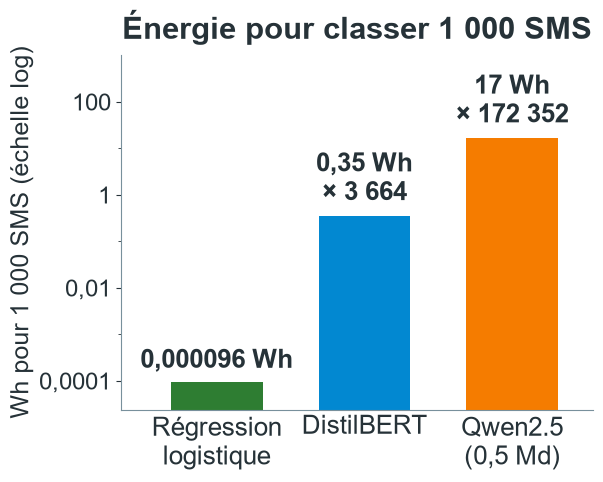

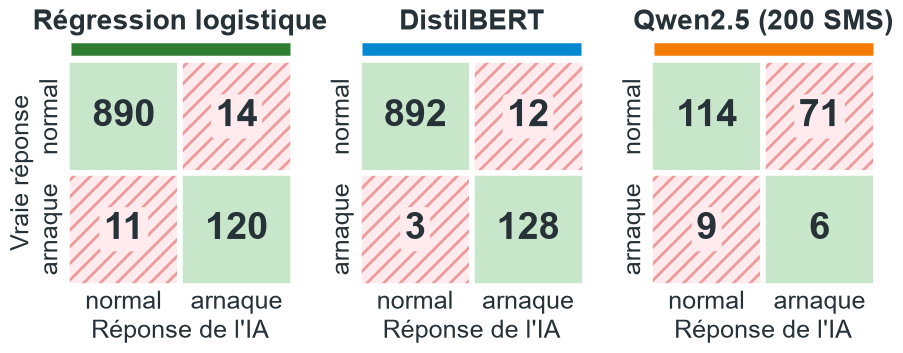

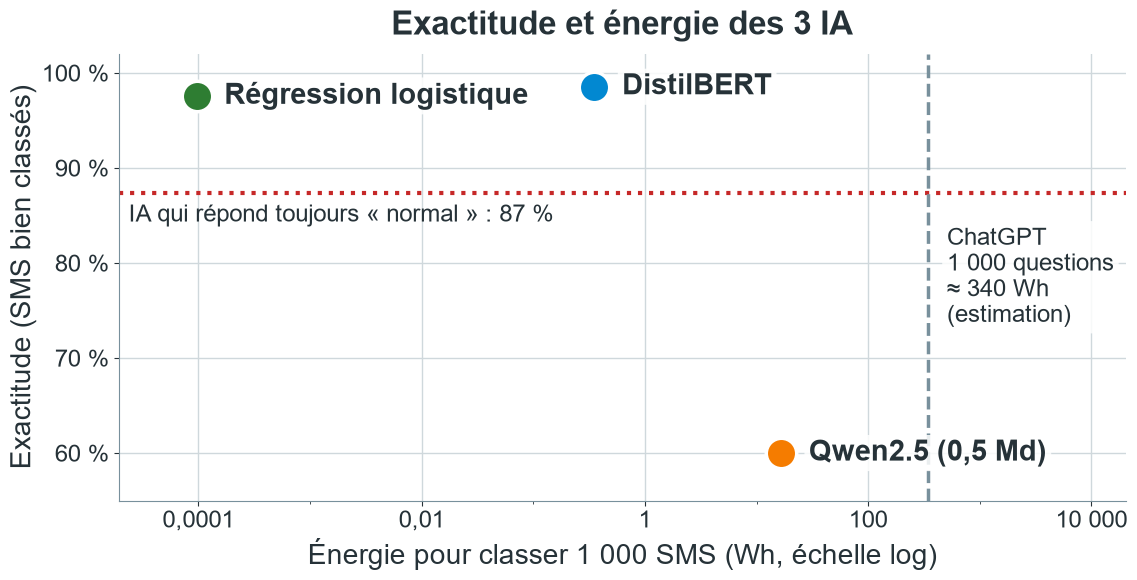

Fichiers enregistrés : energie_barres, matrices_confusion, exactitude_vs_energie (.pdf pour le poster)


In [30]:
# ✏️ v5 (Anis) : les 3 graphes du poster, aux couleurs du poster.
# Case à mettre tout à la fin du notebook (partie 12) : elle utilise df, y_test, y_llm et les mesures.
# Les figures sont dessinées à leur taille sur l'affiche A0, avec de gros caractères.
# Elles sont enregistrées en .pdf (pour le poster) et en .png (pour regarder).
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, LogLocator, MaxNLocator, NullFormatter
from sklearn.metrics import confusion_matrix

COULEURS = ["#2E7D32", "#0288D1", "#F57C00"]   # vélo vert, voiture bleue, camion orange (comme sur le poster)
NOMS_COURTS = ["Régression\nlogistique", "DistilBERT", "Qwen2.5\n(0,5 Md)"]
ENCRE = "#263238"                                # couleur du texte
STYLE = {"font.family": "sans-serif",
         "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
         "font.size": 18, "text.color": ENCRE, "axes.labelcolor": ENCRE,
         "xtick.color": ENCRE, "ytick.color": ENCRE, "axes.edgecolor": "#78909C",
         "axes.spines.top": False, "axes.spines.right": False, "hatch.linewidth": 2,
         "pdf.fonttype": 42}

# une seule ligne par IA (si une case a tourné deux fois, on garde la dernière mesure),
# toujours dans l'ordre vélo, voiture, camion
donnees_graphes = df.drop_duplicates(subset="modele", keep="last").copy()
donnees_graphes["rang"] = [0 if "gression" in nom else 1 if "BERT" in nom else 2 for nom in donnees_graphes["modele"]]
donnees_graphes = donnees_graphes.sort_values("rang").reset_index(drop=True)
energies = donnees_graphes["energie_1000_sms_Wh"].to_numpy(dtype=float)
exactitudes = donnees_graphes["accuracy"].to_numpy(dtype=float) * 100


def joli_nombre(v):
    """Écrit un nombre à la française : virgule, espace des milliers, 2 chiffres significatifs."""
    if v >= 10:
        return f"{v:,.0f}".replace(",", " ")
    return np.format_float_positional(v, precision=2, unique=False, fractional=False, trim="-").replace(".", ",")


def axe_log_lisible(axe):
    """Échelle log avec des nombres écrits en entier (0,0001 · 0,01 · 1 · 100…) au lieu de 10⁻⁴."""
    axe.set_major_locator(LogLocator(base=100))
    axe.set_minor_locator(LogLocator(base=10, subs=(1.0,)))
    axe.set_major_formatter(FuncFormatter(lambda v, _: joli_nombre(v)))
    axe.set_minor_formatter(NullFormatter())


# ---------- 1. Énergie des 3 IA (barres, échelle log) ----------
with plt.rc_context(STYLE):
    fig, ax = plt.subplots(figsize=(6.1, 4.6))            # environ 14 x 12 cm sur le poster
    barres = ax.bar(NOMS_COURTS[:len(energies)], energies, color=COULEURS[:len(energies)], width=0.62)
    ax.set_yscale("log")
    ax.set_ylim(energies.min() / 4, energies.max() * 60)
    ax.set_xlim(-0.65, len(energies) - 0.45)
    axe_log_lisible(ax.yaxis)
    for barre, e in zip(barres, energies):
        fois = e / energies[0]
        texte = joli_nombre(e) + " Wh" + ("\n× " + joli_nombre(fois) if fois >= 1.5 else "")
        ax.annotate(texte, (barre.get_x() + barre.get_width() / 2, e), xytext=(0, 6),
                    textcoords="offset points", ha="center", va="bottom", fontsize=19, fontweight="bold")
    ax.set_ylabel("Wh pour 1 000 SMS (échelle log)", fontsize=18)
    ax.tick_params(axis="x", labelsize=19, length=0)
    ax.tick_params(axis="y", labelsize=17)
    ax.set_title("Énergie pour classer 1 000 SMS", fontsize=22, fontweight="bold", pad=12)
    fig.savefig("energie_barres.pdf", bbox_inches="tight")
    fig.savefig("energie_barres.png", dpi=300, bbox_inches="tight")
    plt.show()

# ---------- 2. Les 3 matrices de confusion, côte à côte ----------
# vert = bonne réponse ; rouge hachuré = erreur (les hachures aident aussi les daltoniens)
paires = [("Régression logistique", y_test, mesure_logreg[0]),
          ("DistilBERT", y_test, mesure_bert[0]),
          (f"Qwen2.5 ({len(y_llm)} SMS)" if len(y_llm) != len(y_test) else "Qwen2.5", y_llm, mesure_llm[0])]
with plt.rc_context(STYLE):
    fig, axes = plt.subplots(1, 3, figsize=(9.2, 4.2))     # environ 23 x 10 cm sur le poster
    for ax, (nom, vrai, predit), couleur in zip(axes, paires, COULEURS):
        m = confusion_matrix(vrai, predit, labels=[0, 1])
        for i in range(2):
            for j in range(2):
                bon = i == j
                ax.add_patch(plt.Rectangle((j, 1 - i), 1, 1, facecolor="#C8E6C9" if bon else "#FFEBEE",
                                           hatch=None if bon else "//", hatchcolor="#EF9A9A",
                                           edgecolor="white", linewidth=4))
                ax.text(j + 0.5, 1.5 - i, str(m[i, j]), ha="center", va="center", fontsize=27, fontweight="bold",
                        bbox=None if bon else dict(boxstyle="round,pad=0.12", facecolor="#FFEBEE", edgecolor="none"))
        ax.plot([0.03, 1.97], [2.1, 2.1], color=couleur, linewidth=9, solid_capstyle="butt", clip_on=False)
        ax.set_xlim(0, 2); ax.set_ylim(0, 2); ax.set_aspect("equal")
        ax.set_xticks([0.5, 1.5], ["normal", "arnaque"], fontsize=18)
        ax.set_yticks([1.5, 0.5], ["normal", "arnaque"], fontsize=18, rotation=90, va="center")
        ax.tick_params(length=0)
        for cote in ax.spines.values():
            cote.set_visible(False)
        ax.set_title(nom, fontsize=20, fontweight="bold", pad=22)
        ax.set_xlabel("Réponse de l'IA", fontsize=18)
    axes[0].set_ylabel("Vraie réponse", fontsize=18)
    fig.tight_layout(w_pad=1.5)
    fig.savefig("matrices_confusion.pdf", bbox_inches="tight")
    fig.savefig("matrices_confusion.png", dpi=300, bbox_inches="tight")
    plt.show()

# ---------- 3. Version « poster » du graphe principal : exactitude vs énergie ----------
# Mêmes informations que la partie 9, aux couleurs du poster, avec les repères écrits sur le graphe.
with plt.rc_context(STYLE):
    reference = (1 - sum(y_test) / len(y_test)) * 100     # % de SMS normaux : score d'une IA qui dit toujours « normal »
    fig, ax = plt.subplots(figsize=(13, 5.8))             # environ 38 x 19 cm sur le poster
    ax.set_xscale("log")
    ax.set_xlim(energies.min() / 5, ESTIMATION_CHATGPT_WH * 60)
    ax.set_ylim(min(exactitudes.min(), reference) - 5, 102)
    axe_log_lisible(ax.xaxis)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6, steps=[1, 2, 5, 10], integer=True))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f} %"))
    ax.grid(True, color="#CFD8DC", linewidth=1)
    ax.set_axisbelow(True)
    ax.axhline(reference, color="#C62828", linestyle=":", linewidth=3, zorder=2)
    ax.annotate(f"IA qui répond toujours « normal » : {reference:.0f} %", (0.01, reference),
                xycoords=("axes fraction", "data"), xytext=(0, -8), textcoords="offset points",
                ha="left", va="top", fontsize=17)
    ax.axvline(ESTIMATION_CHATGPT_WH, color="#78909C", linestyle="--", linewidth=2.5, zorder=2)
    bas, haut = ax.get_ylim()                             # texte « ChatGPT » : en haut, au milieu ou en bas,
    hauteur_texte = max([0.8, 0.5, 0.2],                  # là où il est le plus loin des points des 3 IA
                        key=lambda h: min(abs(h - (y - bas) / (haut - bas)) for y in exactitudes))
    ax.annotate(f"ChatGPT\n1 000 questions\n≈ {joli_nombre(ESTIMATION_CHATGPT_WH)} Wh\n(estimation)",
                (ESTIMATION_CHATGPT_WH, hauteur_texte), xycoords=("data", "axes fraction"), xytext=(14, 0),
                textcoords="offset points", ha="left", va="center", fontsize=17, zorder=4,
                bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="none", alpha=0.85))
    for i in range(len(energies)):
        ax.scatter(energies[i], exactitudes[i], s=480, color=COULEURS[i], edgecolor="white", linewidth=2.5, zorder=3)
        ax.annotate(NOMS_COURTS[i].replace("\n", " "), (energies[i], exactitudes[i]), xytext=(20, 0),
                    textcoords="offset points", ha="left", va="center", fontsize=21, fontweight="bold", zorder=4,
                    bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none", alpha=0.85))
    ax.set_xlabel("Énergie pour classer 1 000 SMS (Wh, échelle log)", fontsize=20)
    ax.set_ylabel("Exactitude (SMS bien classés)", fontsize=20)
    ax.tick_params(labelsize=17)
    ax.set_title("Exactitude et énergie des 3 IA", fontsize=24, fontweight="bold", pad=14)
    fig.savefig("exactitude_vs_energie.pdf", bbox_inches="tight")
    fig.savefig("exactitude_vs_energie_poster.png", dpi=300, bbox_inches="tight")
    plt.show()

print("Fichiers enregistrés : energie_barres, matrices_confusion, exactitude_vs_energie (.pdf pour le poster)")